<a href="https://colab.research.google.com/github/Hoseasunny/skills-introduction-to-github/blob/main/IND_30_G06_Hosea_Wamathai_CT204_109976_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

C1. Regression on Auto MPG

In [94]:
import pandas as pd

In [95]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    silhouette_score
)

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully!
NumPy version: 2.1.3
Pandas version: 2.2.3


In [96]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo
auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets

df = X.copy()
df["mpg"] = y["mpg"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (398, 8)

First five rows:


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB

Missing values in each column:
displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


In [97]:
print("Summary statistics:")
display(df.describe())

print("\nUnique values in categorical-like columns:")
print("Cylinders:", sorted(df["cylinders"].unique()))
print("Origin:", sorted(df["origin"].unique()))

print("\nTarget variable (MPG) statistics:")
print(df["mpg"].describe())



Summary statistics:


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000



Unique values in categorical-like columns:
Cylinders: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(8)]
Origin: [np.int64(1), np.int64(2), np.int64(3)]

Target variable (MPG) statistics:
count    398.000000
mean      23.514573
std        7.815984
min        9.000000
25%       17.500000
50%       23.000000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64


In [98]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets

df = X.copy()
df["mpg"] = y["mpg"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (398, 8)


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


In [99]:
print(df.isnull().sum())

displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


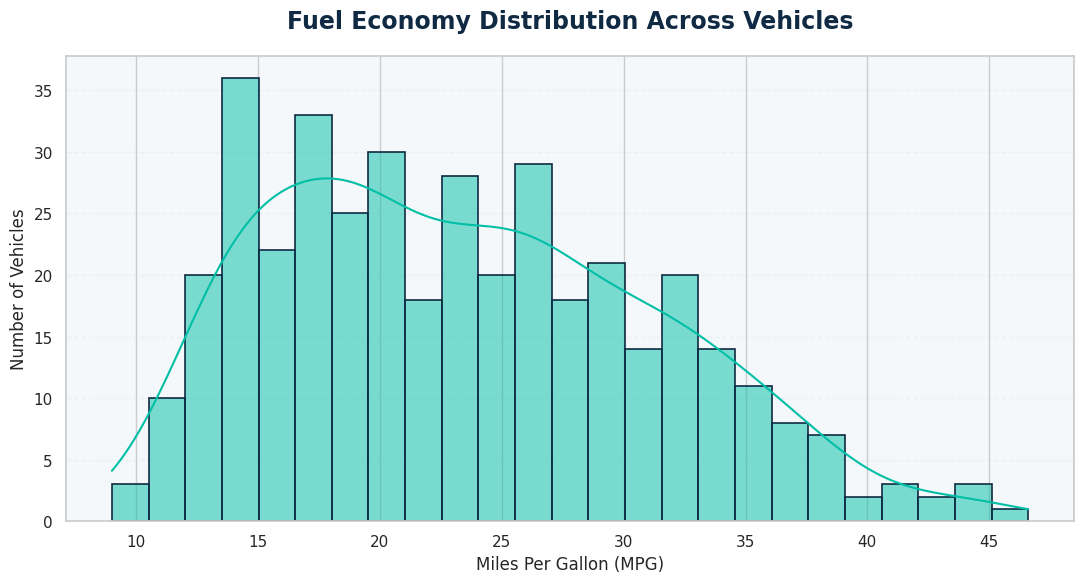

In [100]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="mpg",
    bins=25,
    kde=True,
    color="#00BFA6",
    edgecolor="#102A43",
    linewidth=1.2
)

plt.title("Fuel Economy Distribution Across Vehicles",
          fontsize=17, fontweight="bold", color="#102A43", pad=20)

plt.xlabel("Miles Per Gallon (MPG)", fontsize=12)
plt.ylabel("Number of Vehicles", fontsize=12)

plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.gca().set_facecolor("#F4F8FB")
plt.tight_layout()
plt.show()

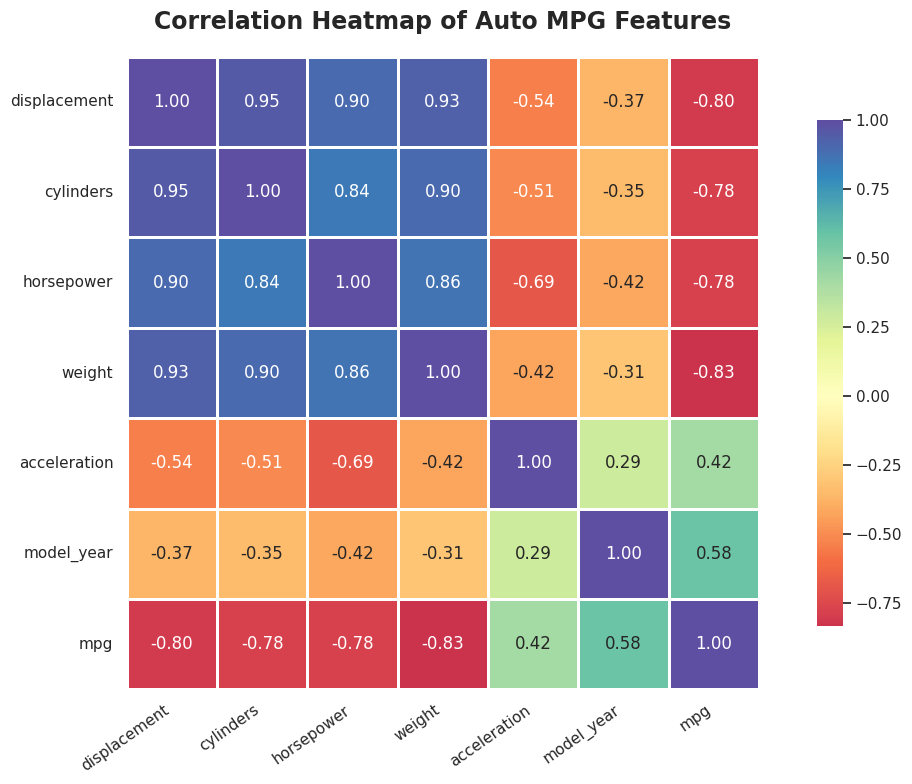

In [101]:
correlation_data = df.drop(columns=["origin"])

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Spectral",
    fmt=".2f",
    linewidths=1,
    linecolor="white",
    center=0,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title(
    "Correlation Heatmap of Auto MPG Features",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [102]:
test_size=0.3
random_state=1694

In [103]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets["mpg"]

print("Dataset loaded successfully!")
print("Original features shape:", X.shape)
print("Target shape:", y.shape)

numerical_features = [
    "displacement",
    "cylinders",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

categorical_features = ["origin"]

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1694
)

print("\nDATA SPLITTING RESULTS")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)



numerical_pipeline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_lr = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline_lr, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])


numerical_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline_rf, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_lr = preprocessor_lr.fit_transform(X_train)
X_test_lr = preprocessor_lr.transform(X_test)

X_train_rf = preprocessor_rf.fit_transform(X_train)
X_test_rf = preprocessor_rf.transform(X_test)


print("\nPREPROCESSING COMPLETED SUCCESSFULLY!")

print("\nLINEAR REGRESSION DATA")
print("Training shape:", X_train_lr.shape)
print("Testing shape:", X_test_lr.shape)

print("\nRANDOM FOREST DATA")
print("Training shape:", X_train_rf.shape)
print("Testing shape:", X_test_rf.shape)

print("\nTARGET DATA")
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nENCODED FEATURE NAMES:")
print(preprocessor_lr.get_feature_names_out())

print("\nRemaining missing values in transformed training data:",
      np.isnan(X_train_lr.toarray() if hasattr(X_train_lr, "toarray")
               else X_train_lr).sum())

print("\nAll preprocessing operations completed!")


Dataset loaded successfully!
Original features shape: (398, 7)
Target shape: (398,)

Numerical features: ['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year']
Categorical features: ['origin']

DATA SPLITTING RESULTS
Training features: (278, 7)
Testing features: (120, 7)
Training targets: (278,)
Testing targets: (120,)

PREPROCESSING COMPLETED SUCCESSFULLY!

LINEAR REGRESSION DATA
Training shape: (278, 9)
Testing shape: (120, 9)

RANDOM FOREST DATA
Training shape: (278, 9)
Testing shape: (120, 9)

TARGET DATA
Training target shape: (278,)
Testing target shape: (120,)

ENCODED FEATURE NAMES:
['numerical__displacement' 'numerical__cylinders' 'numerical__horsepower'
 'numerical__weight' 'numerical__acceleration' 'numerical__model_year'
 'categorical__origin_1' 'categorical__origin_2' 'categorical__origin_3']

Remaining missing values in transformed training data: 0

All preprocessing operations completed!


In [104]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets["mpg"]

print("Dataset loaded successfully!")
print("Original features shape:", X.shape)
print("Target shape:", y.shape)

numerical_features = [
    "displacement",
    "cylinders",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

categorical_features = ["origin"]

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1694
)

print("\nDATA SPLITTING RESULTS")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


numerical_pipeline_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline_lr, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])


numerical_pipeline_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline_rf, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_lr = preprocessor_lr.fit_transform(X_train)
X_test_lr = preprocessor_lr.transform(X_test)

X_train_rf = preprocessor_rf.fit_transform(X_train)
X_test_rf = preprocessor_rf.transform(X_test)

print("\nPREPROCESSING COMPLETED SUCCESSFULLY!")

print("\nLINEAR REGRESSION DATA")
print("Training shape:", X_train_lr.shape)
print("Testing shape:", X_test_lr.shape)

print("\nRANDOM FOREST DATA")
print("Training shape:", X_train_rf.shape)
print("Testing shape:", X_test_rf.shape)

print("\nTARGET DATA")
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nENCODED FEATURE NAMES:")
print(preprocessor_lr.get_feature_names_out())

print("\nRemaining missing values in transformed training data:",
      np.isnan(X_train_lr.toarray() if hasattr(X_train_lr, "toarray")
               else X_train_lr).sum())

print("\nAll preprocessing operations completed!")


Dataset loaded successfully!
Original features shape: (398, 7)
Target shape: (398,)

Numerical features: ['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year']
Categorical features: ['origin']

DATA SPLITTING RESULTS
Training features: (278, 7)
Testing features: (120, 7)
Training targets: (278,)
Testing targets: (120,)

PREPROCESSING COMPLETED SUCCESSFULLY!

LINEAR REGRESSION DATA
Training shape: (278, 9)
Testing shape: (120, 9)

RANDOM FOREST DATA
Training shape: (278, 9)
Testing shape: (120, 9)

TARGET DATA
Training target shape: (278,)
Testing target shape: (120,)

ENCODED FEATURE NAMES:
['numerical__displacement' 'numerical__cylinders' 'numerical__horsepower'
 'numerical__weight' 'numerical__acceleration' 'numerical__model_year'
 'categorical__origin_1' 'categorical__origin_2' 'categorical__origin_3']

Remaining missing values in transformed training data: 0

All preprocessing operations completed!


In [105]:


X = df.drop(columns=["mpg"]).copy()
y = df["mpg"].astype(float)

categorical_features = ["cylinders", "origin"]

numeric_features = [
    column for column in X.columns
    if column not in categorical_features
]

X[categorical_features] = X[categorical_features].astype(str)

print("FEATURES (X)")
display(X.head())

print("\nTARGET (y)")
display(y.head())

print("\nCategorical features:", categorical_features)
print("Numerical features:", numeric_features)

FEATURES (X)


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1



TARGET (y)


,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0



Categorical features: ['cylinders', 'origin']
Numerical features: ['displacement', 'horsepower', 'weight', 'acceleration', 'model_year']


In [106]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [107]:
linear_model = LinearRegression()

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=1694
)

In [108]:
linear_model.fit(X_train_lr, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [109]:
random_forest_model.fit(X_train_rf, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [110]:

lr_predictions = linear_model.predict(X_test_lr)

rf_predictions = random_forest_model.predict(X_test_rf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [111]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [112]:
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Evaluation metrics calculated successfully!")

Evaluation metrics calculated successfully!


In [113]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R² Score": [lr_r2, rf_r2]
})

results = results.round(3)

display(results)

,Model,MAE,RMSE,R² Score
0,Linear Regression,2.629,3.473,0.810
1,Random Forest,2.067,2.732,0.883


In [114]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

In [115]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

lr_preprocessor = ColumnTransformer([
    ("numerical", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

rf_preprocessor = ColumnTransformer([
    ("numerical", SimpleImputer(strategy="median"), numerical_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

lr_cv_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("model", LinearRegression())
])

rf_cv_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=1694
    ))
])

In [116]:
lr_cv_scores = cross_val_score(
    lr_cv_model, X_train, y_train,
    cv=5, scoring="r2"
)

rf_cv_scores = cross_val_score(
    rf_cv_model, X_train, y_train,
    cv=5, scoring="r2"
)

print("Linear Regression CV R²:", lr_cv_scores)
print("Random Forest CV R²:", rf_cv_scores)

print("\nMean CV R²:")
print("Linear Regression:", lr_cv_scores.mean())
print("Random Forest:", rf_cv_scores.mean())

Linear Regression CV R²: [0.81616504 0.81629082 0.7800935  0.87347609 0.89731606]
Random Forest CV R²: [0.77770451 0.86426948 0.83020441 0.87605495 0.89519524]

Mean CV R²:
Linear Regression: 0.8366683017347972
Random Forest: 0.8486857174116136


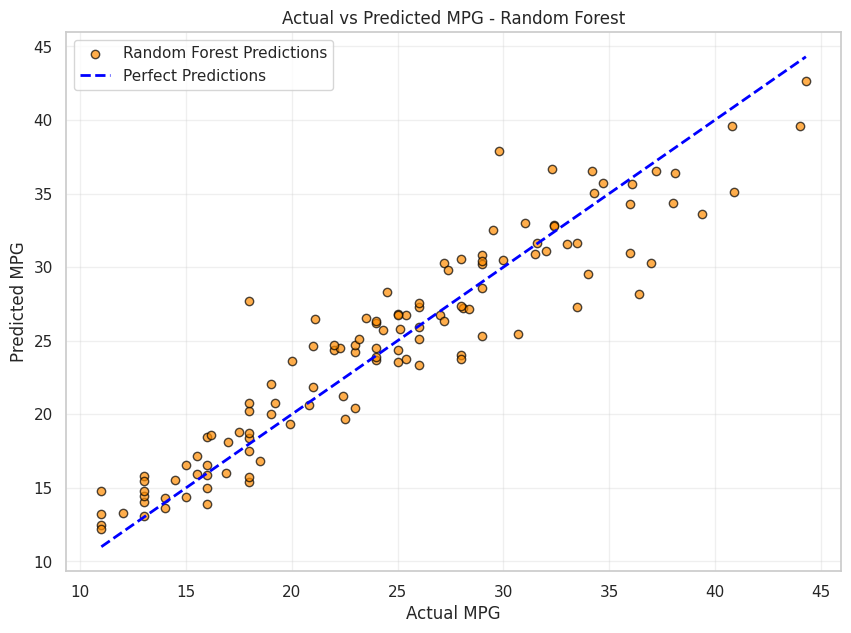

In [117]:
plt.figure(figsize=(10, 7))

plt.scatter(
    y_test,
    rf_predictions,
    color="darkorange",
    alpha=0.7,
    edgecolor="black",
    label="Random Forest Predictions"
)

minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Perfect Predictions"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

C2: Classification on Bank Marketing (15 Marks)

1. Exploratory Data Analysis (EDA)
 2. Data Preprocessing
 3. Train-Test Split
 4. Model Training
 5. Model Evaluation
 6. 5-Fold Stratified Cross-Validation
7. Model Comparison and Interpretation

In [118]:
# Load Bank Marketing dataset
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

bank_marketing = fetch_ucirepo(id=222)

# Separate features and target
X_bank = bank_marketing.data.features
y_bank = bank_marketing.data.targets["y"]

# Create a combined DataFrame for EDA
bank_df = X_bank.copy()
bank_df["y"] = y_bank

print("Bank Marketing dataset loaded successfully!")

Bank Marketing dataset loaded successfully!


In [119]:
print("Dataset shape:", bank_df.shape)

print("\nFirst five records:")
display(bank_df.head())

print("\nDataset information:")
bank_df.info()

Dataset shape: (45211, 17)

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [120]:
# Summary statistics for numerical columns
print("NUMERICAL SUMMARY STATISTICS")
display(bank_df.describe())

# Summary statistics for categorical columns
print("CATEGORICAL SUMMARY STATISTICS")
display(bank_df.describe(include="object"))

NUMERICAL SUMMARY STATISTICS


,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


CATEGORICAL SUMMARY STATISTICS


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,44923,45211,43354,45211,45211,45211,32191,45211,8252,45211
unique,11,3,3,2,2,2,2,12,3,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,failure,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,4901,39922


In [121]:
# Count missing values
missing_values = bank_df.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    bank_df.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


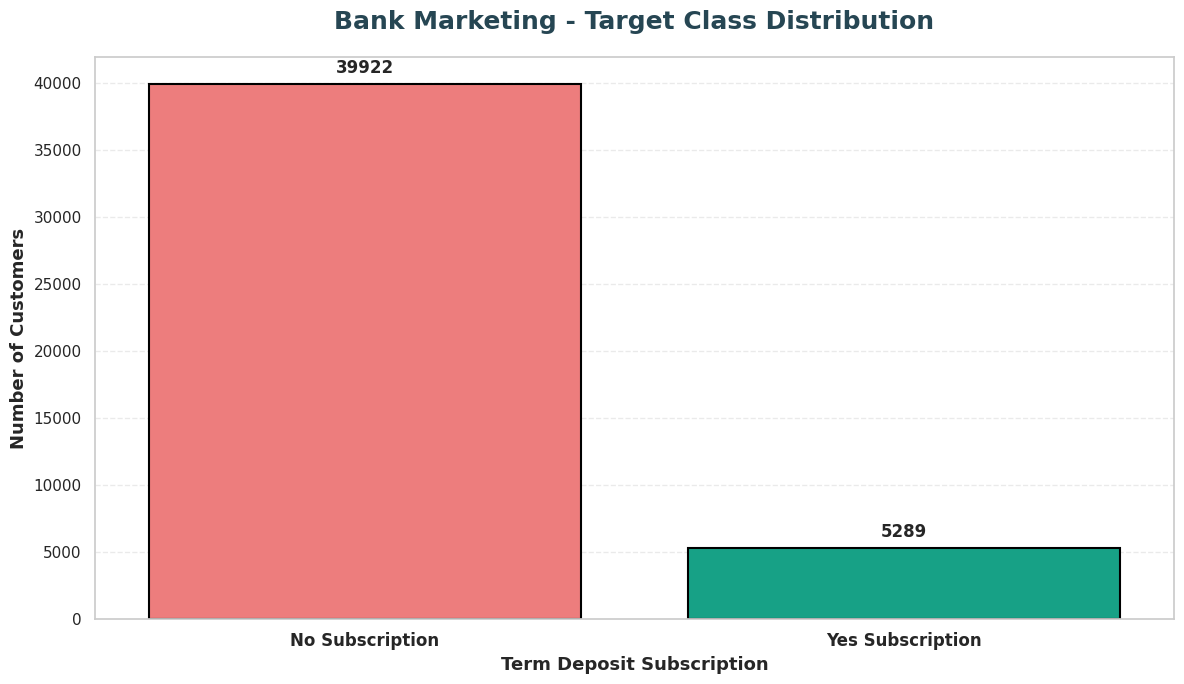

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean plotting theme
sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(12, 7))

sns.countplot(
    data=bank_df,
    x="y",
    hue="y",
    palette={"no": "#FF6B6B", "yes": "#00B894"},
    legend=False,
    edgecolor="black",
    linewidth=1.5
)

# Add chart title and labels
plt.title(
    "Bank Marketing - Target Class Distribution",
    fontsize=18,
    fontweight="bold",
    color="#264653",
    pad=20
)

plt.xlabel(
    "Term Deposit Subscription",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Number of Customers",
    fontsize=13,
    fontweight="bold"
)

# Improve tick labels
plt.xticks(
    ticks=[0, 1],
    labels=["No Subscription", "Yes Subscription"],
    fontsize=12,
    fontweight="bold"
)

plt.yticks(fontsize=11)

# Add horizontal grid lines
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Add customer counts above each bar
ax = plt.gca()

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [123]:
print("The target variable is imbalanced.")
print("Most customers did not subscribe to a term deposit.")
print("Only a smaller proportion subscribed.")
print("Therefore, accuracy alone may not be sufficient")
print("for evaluating the classification models.")

The target variable is imbalanced.
Most customers did not subscribe to a term deposit.
Only a smaller proportion subscribed.
Therefore, accuracy alone may not be sufficient
for evaluating the classification models.


In [124]:
missing_values = bank_df.isnull().sum()
missing_percentage = bank_df.isnull().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


In [125]:
print("Missing Value Analysis:")
print("poutcome has the highest missing percentage (81.75%).")
print("contact has 28.80% missing values.")
print("education and job have fewer missing values.")
print("No missing values were found in the target variable.")
print("Missing values will be handled during preprocessing.")

Missing Value Analysis:
poutcome has the highest missing percentage (81.75%).
contact has 28.80% missing values.
education and job have fewer missing values.
No missing values were found in the target variable.
Missing values will be handled during preprocessing.


In [126]:
# Copy the input features and exclude duration
X_bank_clean = X_bank.drop(columns=["duration"])

# Keep the target variable
y_bank_clean = y_bank.copy()

print("Features after excluding duration:", X_bank_clean.shape)
print("Target shape:", y_bank_clean.shape)

print("\nRemaining features:")
print(X_bank_clean.columns.tolist())

Features after excluding duration: (45211, 15)
Target shape: (45211,)

Remaining features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [127]:
# Identify numerical features
numeric_features_bank = X_bank_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features
categorical_features_bank = X_bank_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features_bank)
print("\nCategorical features:", categorical_features_bank)

Numerical features: ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [128]:
from sklearn.model_selection import train_test_split

X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(
    X_bank_clean,
    y_bank_clean,
    test_size=0.3,
    random_state=1694,
    stratify=y_bank_clean
)

print("Training features:", X_bank_train.shape)
print("Testing features:", X_bank_test.shape)

print("\nTraining target distribution:")
print(y_bank_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_bank_test.value_counts(normalize=True) * 100)

Training features: (31647, 15)
Testing features: (13564, 15)

Training target distribution:
y
no     88.302209
yes    11.697791
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.299912
yes    11.700088
Name: proportion, dtype: float64


In [129]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing for Logistic Regression
numeric_transformer_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_bank = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Logistic Regression preprocessing
preprocessor_lr_bank = ColumnTransformer(transformers=[
    ("num", numeric_transformer_lr, numeric_features_bank),
    ("cat", categorical_transformer_bank, categorical_features_bank)
])

# Random Forest preprocessing (without scaling)
numeric_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_rf_bank = ColumnTransformer(transformers=[
    ("num", numeric_transformer_rf, numeric_features_bank),
    ("cat", categorical_transformer_bank, categorical_features_bank)
])

print("Both preprocessing pipelines created successfully!")

Both preprocessing pipelines created successfully!


In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Create Logistic Regression pipeline
logistic_model_bank = Pipeline(steps=[
    ("preprocessor", preprocessor_lr_bank),
    ("classifier", LogisticRegression(max_iter=1000, random_state=1694))
])

# Create Random Forest pipeline
random_forest_model_bank = Pipeline(steps=[
    ("preprocessor", preprocessor_rf_bank),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=1694,
        n_jobs=-1
    ))
])

# Train Logistic Regression
logistic_model_bank.fit(X_bank_train, y_bank_train)

# Train Random Forest
random_forest_model_bank.fit(X_bank_train, y_bank_train)

print("Logistic Regression trained successfully!")
print("Random Forest trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [131]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_pred_lr_bank = logistic_model_bank.predict(X_bank_test)
y_pred_rf_bank = random_forest_model_bank.predict(X_bank_test)

# Get probability of subscribing (yes)
y_prob_lr_bank = logistic_model_bank.predict_proba(X_bank_test)[:, 1]
y_prob_rf_bank = random_forest_model_bank.predict_proba(X_bank_test)[:, 1]

# Evaluation function
def evaluate_bank_model(name, y_true, y_pred, y_prob):
    print(f"\n{name}")
    print("-" * 40)

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=["no", "yes"]))

    print("\nAccuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(
        precision_score(y_true, y_pred, pos_label="yes", zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_true, y_pred, pos_label="yes", zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_true, y_pred, pos_label="yes", zero_division=0), 4
    ))
    print("ROC-AUC:", round(roc_auc_score(
        (y_true == "yes").astype(int), y_prob
    ), 4))


# Evaluate Logistic Regression
evaluate_bank_model(
    "LOGISTIC REGRESSION",
    y_bank_test,
    y_pred_lr_bank,
    y_prob_lr_bank
)

# Evaluate Random Forest
evaluate_bank_model(
    "RANDOM FOREST",
    y_bank_test,
    y_pred_rf_bank,
    y_prob_rf_bank
)


LOGISTIC REGRESSION
----------------------------------------
Confusion Matrix:
[[11802   175]
 [ 1316   271]]

Accuracy: 0.8901
Precision: 0.6076
Recall: 0.1708
F1-score: 0.2666
ROC-AUC: 0.7552

RANDOM FOREST
----------------------------------------
Confusion Matrix:
[[11721   256]
 [ 1230   357]]

Accuracy: 0.8904
Precision: 0.5824
Recall: 0.225
F1-score: 0.3245
ROC-AUC: 0.7755


In [132]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

# Create 5 stratified folds
bank_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1694
)

# Define evaluation metrics
bank_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="yes", zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label="yes", zero_division=0
    ),
    "roc_auc": "roc_auc"
}

# Cross-validation for Logistic Regression
cv_lr_bank = cross_validate(
    logistic_model_bank,
    X_bank_clean,
    y_bank_clean,
    cv=bank_cv,
    scoring=bank_scoring,
    n_jobs=-1
)

# Cross-validation for Random Forest
cv_rf_bank = cross_validate(
    random_forest_model_bank,
    X_bank_clean,
    y_bank_clean,
    cv=bank_cv,
    scoring=bank_scoring,
    n_jobs=-1
)

# Display average scores
bank_cv_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        cv_lr_bank["test_accuracy"].mean(),
        cv_lr_bank["test_precision"].mean(),
        cv_lr_bank["test_recall"].mean(),
        cv_lr_bank["test_f1"].mean(),
        cv_lr_bank["test_roc_auc"].mean()
    ],
    "Random Forest": [
        cv_rf_bank["test_accuracy"].mean(),
        cv_rf_bank["test_precision"].mean(),
        cv_rf_bank["test_recall"].mean(),
        cv_rf_bank["test_f1"].mean(),
        cv_rf_bank["test_roc_auc"].mean()
    ]
})

display(bank_cv_results.round(4))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8926,0.8939
1,Precision,0.6477,0.6205
2,Recall,0.1794,0.2384
3,F1-score,0.2809,0.3444
4,ROC-AUC,0.7651,0.7787


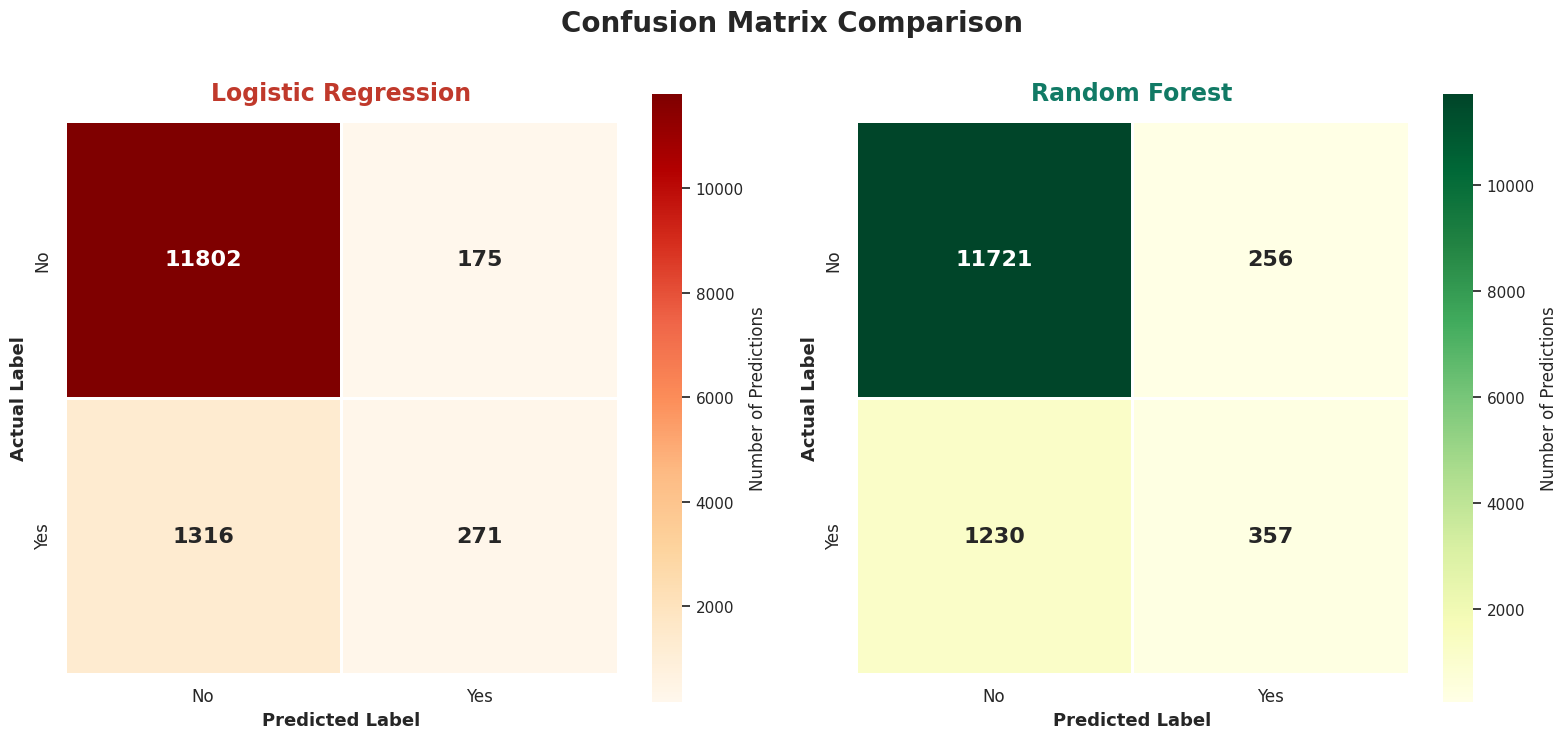

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Set a colourful visual theme
sns.set_theme(style="whitegrid", context="notebook")

# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Logistic Regression confusion matrix
cm_lr_bank = confusion_matrix(
    y_bank_test, y_pred_lr_bank, labels=["no", "yes"]
)

sns.heatmap(
    cm_lr_bank,
    annot=True,
    fmt="d",
    cmap="OrRd",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    linewidths=2,
    linecolor="white",
    square=True,
    annot_kws={"size": 16, "weight": "bold"},
    cbar_kws={"label": "Number of Predictions"},
    ax=axes[0]
)

axes[0].set_title(
    "Logistic Regression",
    fontsize=17,
    fontweight="bold",
    color="#C0392B",
    pad=15
)

axes[0].set_xlabel(
    "Predicted Label",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Actual Label",
    fontsize=13,
    fontweight="bold"
)

axes[0].tick_params(axis="both", labelsize=12)

# Random Forest confusion matrix
cm_rf_bank = confusion_matrix(
    y_bank_test, y_pred_rf_bank, labels=["no", "yes"]
)

sns.heatmap(
    cm_rf_bank,
    annot=True,
    fmt="d",
    cmap="YlGn",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    linewidths=2,
    linecolor="white",
    square=True,
    annot_kws={"size": 16, "weight": "bold"},
    cbar_kws={"label": "Number of Predictions"},
    ax=axes[1]
)

axes[1].set_title(
    "Random Forest",
    fontsize=17,
    fontweight="bold",
    color="#117A65",
    pad=15
)

axes[1].set_xlabel(
    "Predicted Label",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Actual Label",
    fontsize=13,
    fontweight="bold"
)

axes[1].tick_params(axis="both", labelsize=12)

# Main heading
plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=20,
    fontweight="bold",
    y=1.03
)

# Adjust spacing between graphs
plt.tight_layout()

# Display both confusion matrices
plt.show()

C3 – Clustering on Country Socio-economic Data

In [134]:
import pandas as pd

country_url = "https://raw.githubusercontent.com/Lakshitha6/Unsupervised-Learning-on-Country-Data/main/data/Country-data.csv"

country_df = pd.read_csv(country_url)

print("Dataset loaded successfully!")
print("Dataset shape:", country_df.shape)

display(country_df.head())

Dataset loaded successfully!
Dataset shape: (167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [135]:
from sklearn.preprocessing import StandardScaler

# Select numerical features only
country_features = country_df.drop(columns=["country"])

# Check for missing values
print("Missing values:")
print(country_features.isnull().sum())

# Standardise the numerical features
country_scaler = StandardScaler()

country_scaled = country_scaler.fit_transform(country_features)

# Convert standardised data back to a DataFrame
country_scaled_df = pd.DataFrame(
    country_scaled,
    columns=country_features.columns
)

print("\nOriginal feature shape:", country_features.shape)
print("Standardised feature shape:", country_scaled_df.shape)

display(country_scaled_df.head())

Missing values:
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Original feature shape: (167, 9)
Standardised feature shape: (167, 9)


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


In [136]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store results
country_inertia = []
country_silhouette = []
country_k_values = range(2, 9)

# Test K-means for k = 2 to 8
for k in country_k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=1694,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(country_scaled_df)

    country_inertia.append(kmeans.inertia_)

    country_silhouette.append(
        silhouette_score(country_scaled_df, cluster_labels)
    )

    print(
        f"k = {k}: "
        f"Inertia = {kmeans.inertia_:.2f}, "
        f"Silhouette Score = {country_silhouette[-1]:.4f}"
    )

k = 2: Inertia = 1050.21, Silhouette Score = 0.2874
k = 3: Inertia = 831.42, Silhouette Score = 0.2833
k = 4: Inertia = 700.52, Silhouette Score = 0.2960
k = 5: Inertia = 631.86, Silhouette Score = 0.2201
k = 6: Inertia = 550.88, Silhouette Score = 0.2301
k = 7: Inertia = 495.81, Silhouette Score = 0.2477
k = 8: Inertia = 452.74, Silhouette Score = 0.2490


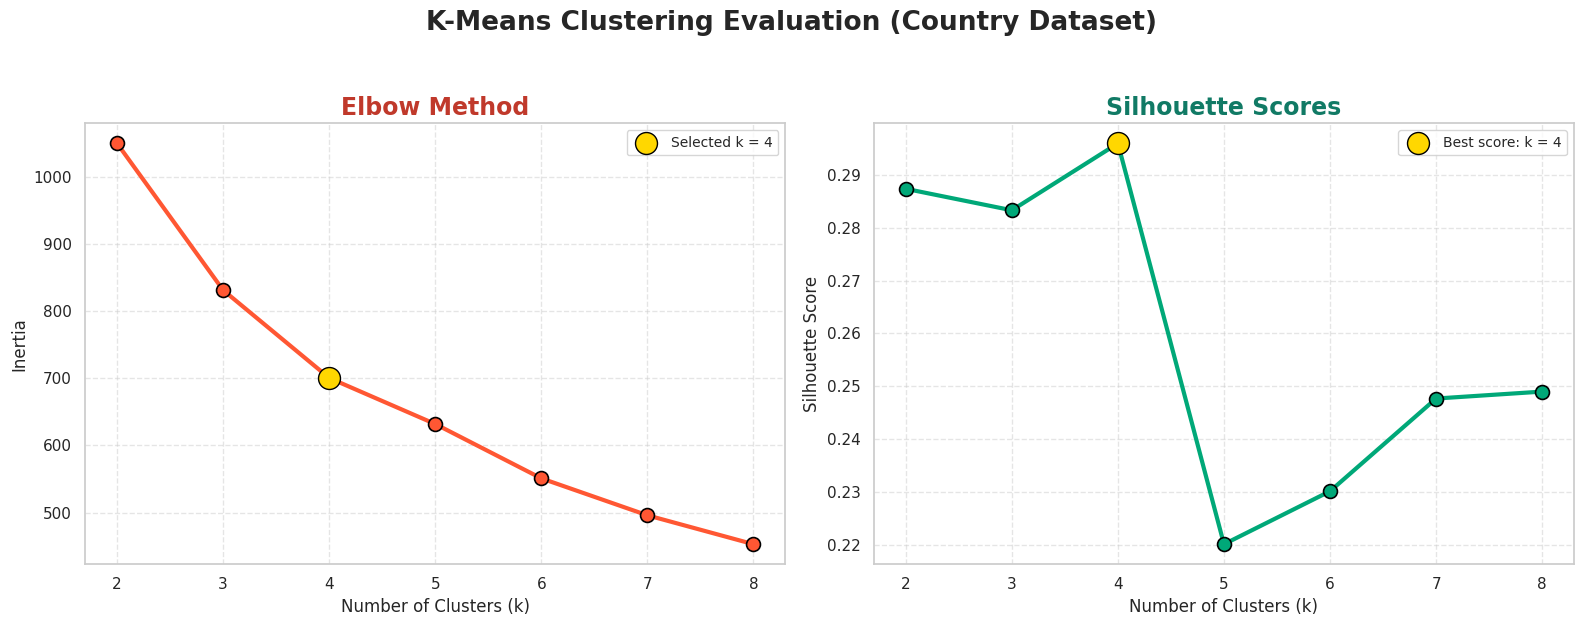

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a colourful visual theme
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Colours
elbow_color = "#FF5733"
silhouette_color = "#00A878"

# ---------------- ELBOW METHOD ----------------

axes[0].plot(
    list(country_k_values),
    country_inertia,
    color=elbow_color,
    marker="o",
    markersize=10,
    linewidth=3,
    markeredgecolor="black",
    markeredgewidth=1.2
)

# Highlight selected k = 4
axes[0].scatter(
    4, country_inertia[2],
    color="#FFD700",
    edgecolors="black",
    s=250,
    zorder=5,
    label="Selected k = 4"
)

axes[0].set_title(
    "Elbow Method",
    fontsize=17,
    fontweight="bold",
    color="#C0392B"
)

axes[0].set_xlabel("Number of Clusters (k)", fontsize=12)
axes[0].set_ylabel("Inertia", fontsize=12)
axes[0].set_xticks(list(country_k_values))
axes[0].tick_params(axis="both", labelsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=10)

# ---------------- SILHOUETTE SCORES ----------------

axes[1].plot(
    list(country_k_values),
    country_silhouette,
    color=silhouette_color,
    marker="o",
    markersize=10,
    linewidth=3,
    markeredgecolor="black",
    markeredgewidth=1.2
)

# Highlight highest silhouette score at k = 4
axes[1].scatter(
    4, country_silhouette[2],
    color="#FFD700",
    edgecolors="black",
    s=250,
    zorder=5,
    label="Best score: k = 4"
)

axes[1].set_title(
    "Silhouette Scores",
    fontsize=17,
    fontweight="bold",
    color="#117A65"
)

axes[1].set_xlabel("Number of Clusters (k)", fontsize=12)
axes[1].set_ylabel("Silhouette Score", fontsize=12)
axes[1].set_xticks(list(country_k_values))
axes[1].tick_params(axis="both", labelsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=10)

# Overall title
fig.suptitle(
    "K-Means Clustering Evaluation (Country Dataset)",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

The optimal number of clusters was selected as four (k = 4). The elbow method showed that the inertia curve began to flatten around k = 4, indicating diminishing improvements when additional clusters were introduced. The silhouette analysis also recorded its highest score of 0.2960 at k = 4, suggesting better cluster separation compared to the other tested values. Therefore, four clusters were selected for the final K-Means model.

In [138]:
# Train the final K-Means model
final_kmeans = KMeans(
    n_clusters=4,
    random_state=1694,
    n_init=10
)

# Assign each country to a cluster
country_cluster_labels = final_kmeans.fit_predict(country_scaled_df)

# Add cluster labels to the original dataset
country_df["cluster"] = country_cluster_labels

# Display the number of countries in each cluster
print("Number of countries in each cluster:")
print(country_df["cluster"].value_counts().sort_index())

Number of countries in each cluster:
cluster
0    47
1    85
2    32
3     3
Name: count, dtype: int64


In [139]:
# Calculate mean values of numerical features for each cluster
country_cluster_profile = country_df.groupby("cluster")[
    country_features.columns
].mean()

print("Average feature values for each cluster:")
display(country_cluster_profile.round(2))

Average feature values for each cluster:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
cluster,,,,,,,,,
0,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38
1,21.69,41.07,6.20,47.91,12671.41,7.61,72.87,2.30,6519.55
2,5.18,46.12,9.09,40.58,44021.88,2.51,80.08,1.79,42118.75
3,4.13,176.00,6.79,156.67,64033.33,2.47,81.43,1.38,57566.67


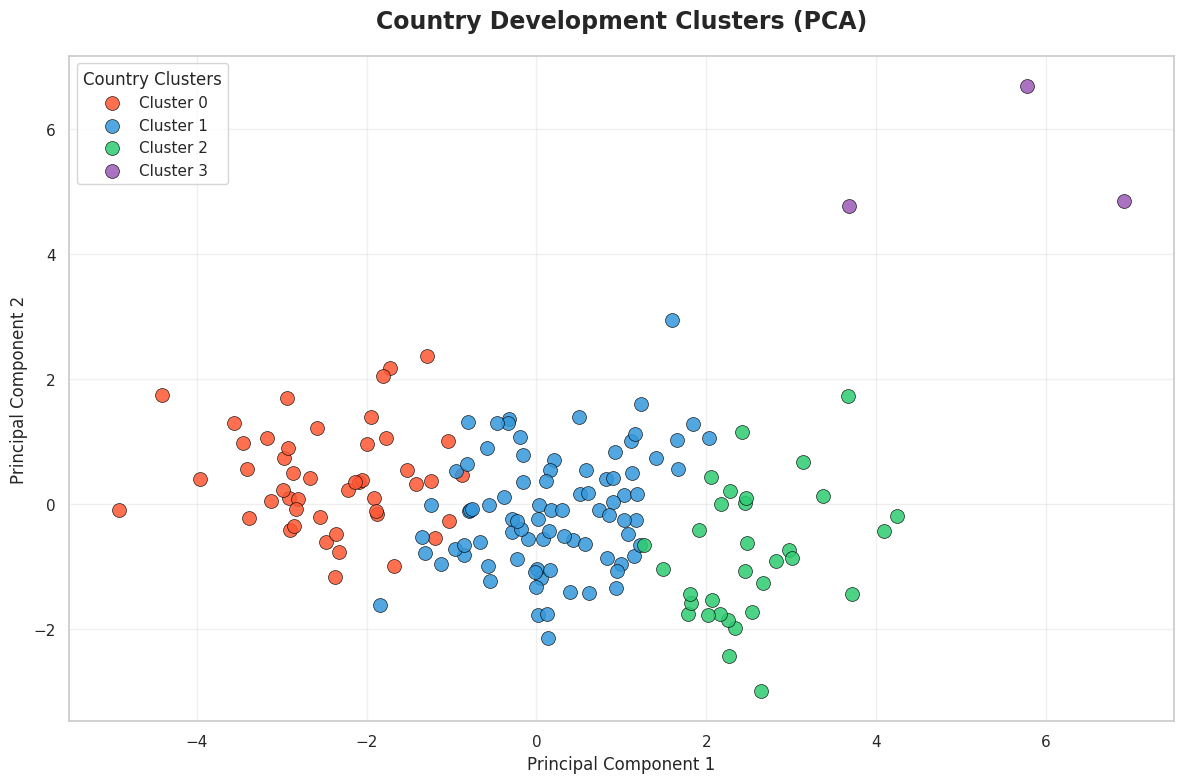

Explained variance: [0.4595174  0.17181626]
Total variance explained: 63.13 %


In [140]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set a colourful theme
sns.set_theme(style="whitegrid", palette="bright")

# Reduce 9 features to 2 dimensions
country_pca = PCA(n_components=2)
country_pca_results = country_pca.fit_transform(country_scaled_df)

# Create PCA DataFrame
country_pca_df = pd.DataFrame(
    country_pca_results,
    columns=["Principal Component 1", "Principal Component 2"]
)

country_pca_df["cluster"] = country_cluster_labels

# Define four distinct colours
cluster_colors = {
    0: "#FF5733",  # Orange-red
    1: "#3498DB",  # Blue
    2: "#2ECC71",  # Green
    3: "#9B59B6"   # Purple
}

# Create colourful PCA plot
plt.figure(figsize=(12, 8))

for cluster in sorted(country_pca_df["cluster"].unique()):
    cluster_data = country_pca_df[
        country_pca_df["cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["Principal Component 1"],
        cluster_data["Principal Component 2"],
        color=cluster_colors[cluster],
        label=f"Cluster {cluster}",
        s=100,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.5
    )

plt.title(
    "Country Development Clusters (PCA)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)

plt.legend(
    title="Country Clusters",
    fontsize=11,
    title_fontsize=12,
    loc="best",
    frameon=True
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Explained variance
print("Explained variance:", country_pca.explained_variance_ratio_)
print(
    "Total variance explained:",
    round(country_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [141]:
print("PC1 variance:", round(
    country_pca.explained_variance_ratio_[0] * 100, 2
), "%")

print("PC2 variance:", round(
    country_pca.explained_variance_ratio_[1] * 100, 2
), "%")

print("Combined variance:", round(
    country_pca.explained_variance_ratio_.sum() * 100, 2
), "%")

PC1 variance: 45.95 %
PC2 variance: 17.18 %
Combined variance: 63.13 %
